# 02 · Data Formats and pandas

Data arrives as CSV, JSON, spreadsheets, databases or columnar files, and the format you store it in
decides how big the files are, how fast they load and what can go wrong. This module covers pandas,
the standard tool for tables in Python, and then measures the common formats on the same data.

**You will learn**
1. The pandas `DataFrame`: create, inspect, select, filter, group
2. Reading and writing CSV, JSON, Excel, Parquet, Feather, SQLite, YAML and pickle
3. Which format to choose, measured: file size, write and read time, types preserved
4. Pitfalls: encodings, dates, types lost in CSV, and why you must never unpickle untrusted data

## 1. The pandas DataFrame
A two-dimensional, labelled table: columns have names and types, rows have an index.

In [1]:
import pandas as pd

df = pd.DataFrame({
    "name": ["Alice", "Bob", "Charlie", "Diana"],
    "age": [30, 25, 35, 28],
    "city": ["Berlin", "Paris", "Berlin", "Madrid"],
    "salary": [62_000, 48_000, 75_000, 51_000],
})
print(df.shape)
print(df.dtypes)
df.head(3)

(4, 4)
name      object
age        int64
city      object
salary     int64
dtype: object


,name,age,city,salary
0,Alice,30,Berlin,62000
1,Bob,25,Paris,48000
2,Charlie,35,Berlin,75000


In [2]:
print(df["name"].tolist())            # one column (a Series)
print(df.loc[0, "city"])               # by label
print(df.iloc[1].to_dict())            # by position
df[(df["age"] > 26) & (df["city"] == "Berlin")]   # boolean filtering

['Alice', 'Bob', 'Charlie', 'Diana']
Berlin
{'name': 'Bob', 'age': 25, 'city': 'Paris', 'salary': 48000}


,name,age,city,salary
0,Alice,30,Berlin,62000
2,Charlie,35,Berlin,75000


In [3]:
df["senior"] = df["age"] >= 30                     # new column
summary = df.groupby("city").agg(people=("name", "count"), mean_salary=("salary", "mean"))
print(summary)
df.describe()

        people  mean_salary
city                       
Berlin       2      68500.0
Madrid       1      51000.0
Paris        1      48000.0


,age,salary
count,4.000000,4.000000
mean,29.500000,59000.000000
std,4.203173,12247.448714
min,25.000000,48000.000000
25%,27.250000,50250.000000
50%,29.000000,56500.000000
75%,31.250000,65250.000000
max,35.000000,75000.000000


## 2. A realistic dataset to compare formats
200,000 rows of synthetic sensor readings with the column types real data has: timestamps, integers,
floats, categories and free text.

In [4]:
import numpy as np

rng = np.random.default_rng(42)
n = 200_000
data = pd.DataFrame({
    "timestamp": pd.date_range("2025-01-01", periods=n, freq="min"),
    "sensor_id": rng.integers(1, 500, n),
    "temperature": rng.normal(21, 4, n).round(2),
    "status": rng.choice(["ok", "warning", "fault"], n, p=[0.9, 0.08, 0.02]),
    "note": rng.choice(["", "manual check", "recalibrated", "battery low"], n),
})
data["status"] = data["status"].astype("category")
print(data.dtypes)
print(f"in memory: {data.memory_usage(deep=True).sum() / 1e6:.1f} MB")

timestamp      datetime64[ns]
sensor_id               int64
temperature           float64
status               category
note                   object
dtype: object


in memory: 16.6 MB


## 3. Write, read and compare
Each format is written and read back three times, and we check whether the column types survive the
round trip.

In [5]:
import os, time, tempfile, sqlite3, warnings
warnings.filterwarnings("ignore")
tmp = tempfile.mkdtemp()

def timed(fn, repeat=3):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); out = fn(); best = min(best, time.perf_counter() - t0)
    return best, out

formats = {
    "CSV":     ("data.csv",     lambda p: data.to_csv(p, index=False),          lambda p: pd.read_csv(p)),
    "CSV.gz":  ("data.csv.gz",  lambda p: data.to_csv(p, index=False),          lambda p: pd.read_csv(p)),
    "JSON":    ("data.json",    lambda p: data.to_json(p, orient="records", date_format="iso"), lambda p: pd.read_json(p, orient="records")),
    "Parquet": ("data.parquet", lambda p: data.to_parquet(p, index=False),      lambda p: pd.read_parquet(p)),
    "Feather": ("data.feather", lambda p: data.to_feather(p),                   lambda p: pd.read_feather(p)),
    "Pickle":  ("data.pkl",     lambda p: data.to_pickle(p),                    lambda p: pd.read_pickle(p)),
    "SQLite":  ("data.db",      lambda p: data.to_sql("readings", sqlite3.connect(p), index=False, if_exists="replace"),
                                lambda p: pd.read_sql("select * from readings", sqlite3.connect(p))),
}
rows = []
for name, (fname, write, read) in formats.items():
    path = os.path.join(tmp, fname)
    t_write, _ = timed(lambda: write(path), repeat=1)
    t_read, back = timed(lambda: read(path))
    same_types = list(back.dtypes.astype(str)) == list(data.dtypes.astype(str))
    rows.append(dict(format=name, size_mb=os.path.getsize(path) / 1e6, write_s=t_write, read_s=t_read, types_kept=same_types))

results = pd.DataFrame(rows).set_index("format").round(3).sort_values("size_mb")
results

,size_mb,write_s,read_s,types_kept
format,,,,
CSV.gz,1.556,2.780,0.326,False
Parquet,2.306,0.184,0.040,True
Feather,4.076,0.050,0.013,True
Pickle,7.305,0.044,0.031,True
CSV,8.580,1.127,0.291,False
SQLite,10.482,1.641,0.712,False
JSON,21.780,0.595,0.975,False


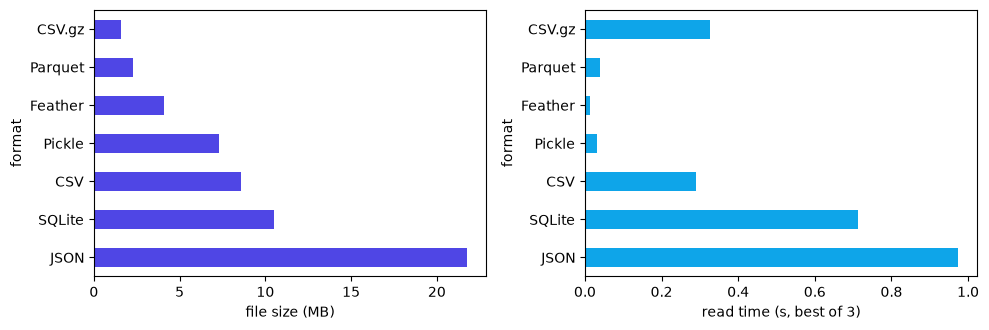

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
results["size_mb"].plot.barh(ax=ax[0], color="#4f46e5"); ax[0].set_xlabel("file size (MB)")
results["read_s"].plot.barh(ax=ax[1], color="#0ea5e9"); ax[1].set_xlabel("read time (s, best of 3)")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.show()

**Reading the result.** Columnar binary formats (Parquet, Feather) are the smallest and fastest *and*
they keep the column types: timestamps stay timestamps and categories stay categories. CSV and JSON lose
types, so `timestamp` comes back as text and `status` as plain strings unless you tell the reader what
to expect:

In [7]:
back = pd.read_csv(os.path.join(tmp, "data.csv"),
                   parse_dates=["timestamp"], dtype={"status": "category"}, keep_default_na=False)
print(back.dtypes)

timestamp      datetime64[ns]
sensor_id               int64
temperature           float64
status               category
note                   object
dtype: object


## 4. Small configuration and exchange formats
Not everything is a table. Configuration lives in YAML, TOML or JSON; APIs exchange JSON.

In [8]:
import json, yaml, tomllib

config = {"model": {"name": "baseline", "layers": [64, 32]}, "train": {"epochs": 10, "lr": 0.001}}
as_json = json.dumps(config, indent=2)
as_yaml = yaml.safe_dump(config, sort_keys=False)
print(as_yaml)
assert json.loads(as_json) == yaml.safe_load(as_yaml) == config

toml_text = '[model]\nname = "baseline"\nlayers = [64, 32]\n\n[train]\nepochs = 10\nlr = 0.001\n'
print(tomllib.loads(toml_text) == config)     # TOML: what pyproject.toml uses (module 07)

model:
  name: baseline
  layers:
  - 64
  - 32
train:
  epochs: 10
  lr: 0.001

True


## 5. Excel
Common in business settings. Slow and type-fragile compared with Parquet, but sometimes the format
the reader needs.

In [9]:
path = os.path.join(tmp, "summary.xlsx")
summary_by_status = data.groupby("status", observed=True)["temperature"].agg(["count", "mean", "max"]).round(2)
with pd.ExcelWriter(path) as xl:
    summary_by_status.to_excel(xl, sheet_name="by_status")
    data.head(100).to_excel(xl, sheet_name="sample", index=False)
print(pd.read_excel(path, sheet_name="by_status"))

    status   count   mean    max
0    fault    4045  20.84  37.87
1       ok  180055  21.01  40.97
2  warning   15900  21.01  35.84


## 6. Pitfalls worth knowing
- **Encodings.** Files from other systems may not be UTF-8: `pd.read_csv(path, encoding="latin-1")`.
- **Decimal and thousands separators.** European CSVs often use `;` and `,`: `pd.read_csv(path, sep=";", decimal=",")`.
- **Dates.** Ambiguous `01/02/2025` means different days in different countries; prefer ISO 8601 (`2025-02-01`).
- **Pickle executes code when loaded.** It is fine for your own cached objects, but never load a pickle
  from an untrusted source. The demonstration below runs a command just by being unpickled:

In [10]:
import pickle

class Malicious:
    def __reduce__(self):                      # tells pickle how to "rebuild" the object
        return (print, ("this ran during pickle.loads: it could have been any command",))

payload = pickle.dumps(Malicious())
pickle.loads(payload)                           # prints: loading executed code

this ran during pickle.loads: it could have been any command


## Which format when?

| Need | Use |
|---|---|
| Analysis data, anything above a few MB | **Parquet** (compressed, typed, columnar, readable by every tool) |
| Fast temporary exchange between Python and R | Feather / Arrow IPC |
| Human-readable, small, universal | CSV (with explicit types on read) |
| Nested data, web APIs | JSON |
| Configuration | YAML or TOML |
| Many writers, queries, transactions | a database (SQLite locally, PostgreSQL on a server) |
| People who live in spreadsheets | Excel |
| Caching your own Python objects | pickle (trusted data only) |

## Exercises
1. Add a `float32` column and check which formats keep `float32` after the round trip.
2. Write the readings to Parquet partitioned by `status` (`partition_cols=["status"]`) and read back only the `fault` rows.
3. Load the CSV with `usecols=["timestamp", "temperature"]` and compare the time with loading everything.